In [108]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
df = pd.read_csv(r"C:\Users\Josephine Mackylah\Desktop\Kenya market prices\data\food-prices-kenya.csv")
df.head()
df.columns


Index(['date', 'region', 'county', 'market', 'commodity', 'price_type', 'unit',
       'price_kes', 'price_usd'],
      dtype='str')

In [109]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2742 entries, 0 to 2741
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        2742 non-null   str    
 1   region      2683 non-null   str    
 2   county      2683 non-null   str    
 3   market      2742 non-null   str    
 4   commodity   2742 non-null   str    
 5   price_type  2742 non-null   str    
 6   unit        2742 non-null   str    
 7   price_kes   2742 non-null   float64
 8   price_usd   2742 non-null   float64
dtypes: float64(2), str(7)
memory usage: 192.9 KB


In [110]:
df.describe()

,price_kes,price_usd
count,2742.000000,2742.000000
mean,2239.335748,25.127372
std,2576.989414,28.185014
min,6.000000,0.074000
25%,55.000000,0.600000
50%,1313.335000,18.170000
75%,3733.000000,45.082500
max,10350.000000,115.150000


In [111]:
df.sample(50)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
1944,2018-07-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,6700.00,66.73
2107,2013-04-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,2833.00,33.85
1553,2013-04-15,Nyanza,Kisumu,Kisumu,Beans,Wholesale,90 KG,7200.00,86.02
2224,2009-02-15,Nyanza,Kisumu,Kisumu,Maize,Wholesale,90 KG,2800.00,35.22
1588,2016-03-15,Nyanza,Kisumu,Kisumu,Beans,Wholesale,90 KG,7808.00,77.00
1284,2018-09-15,Eastern,Marsabit,Marsabit,Maize,Retail,KG,41.00,0.41
360,2016-05-15,North Eastern,Garissa,Garissa,Maize,Retail,KG,51.00,0.51
554,2017-10-15,Coast,Kilifi,Kilifi,Maize,Retail,KG,39.20,0.38
2550,2008-11-15,Nairobi,Nairobi,Nairobi,Maize,Wholesale,90 KG,2618.00,33.59
1892,2014-02-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,6147.00,71.24


In [112]:
#turn the date column into real date
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["date"].sample(20, random_state=42)

859    2015-04-15
1521   2010-08-15
1322   2007-11-15
1352   2010-05-15
2031   2006-11-15
2518   2006-03-15
2201   2007-02-15
798    2010-02-15
1110   2017-06-15
1900   2014-10-15
1364   2011-05-15
1102   2016-10-15
1601   2017-05-15
1179   2009-06-15
2030   2006-10-15
677    2014-01-15
1117   2018-01-15
1607   2017-11-15
1820   2008-02-15
2104   2013-01-15
Name: date, dtype: datetime64[us]

In [113]:
# add year and month columns
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df.sample(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
1200,2011-03-15,Eastern,Marsabit,Marsabit,Maize,Retail,KG,36.0,0.42,2011,3
2197,2006-10-15,Nyanza,Kisumu,Kisumu,Maize,Wholesale,90 KG,1282.0,17.78,2006,10
1593,2016-09-15,Nyanza,Kisumu,Kisumu,Beans,Wholesale,90 KG,7200.0,71.22,2016,9
707,2016-07-15,Eastern,Kitui,Kitui,Maize,Retail,KG,31.0,0.31,2016,7
365,2016-10-15,North Eastern,Garissa,Garissa,Maize,Retail,KG,55.0,0.54,2016,10


In [114]:
#fill the missing county and region for the market that has none.
df["county"].isna().sum()
df["region"].isna().sum()

np.int64(59)

In [115]:
# Hola is located in Tana River county within the Coast region
df.loc[df['market'] == 'Hola', 'county'] = df.loc[df['market'] == 'Hola', 'county'].fillna('Tana River')
df.loc[df['market'] == 'Hola', 'region'] = df.loc[df['market'] == 'Hola', 'region'].fillna('Coast')

In [116]:
df.duplicated().sum()

np.int64(0)

In [117]:
nulls = (
    df[df["county"].isna()]          # keep only rows where county is missing
    .groupby("market")
    .size()
    .sort_values(ascending=False)
)
print(nulls)

Series([], dtype: int64)


In [118]:
#How many rows, markets and commodities does the file have, and what are the first and last dates
print(df.shape)

(2742, 11)


In [119]:
df_sorted = df.sort_values("date")
df_sorted.iloc[0]["date"]                
df_sorted.iloc[-1]["date"]
df.head(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96,2015,1
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90,2015,2
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89,2015,3
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91,2015,4
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94,2015,5


In [120]:
#sorting the date from the earliest to the latest date
highest_date = df["date"].max()
print(highest_date)
lowest_date = df["date"].min()
print(lowest_date)

2019-12-15 00:00:00
2006-01-15 00:00:00


In [121]:


""" Compare like with like
Split the data into wholesale (per 90 KG bag) and retail (per KG) prices and never average them together. 
Add a price_per_kg column so you can compare what a trader pays per KG with what a household pays per KG.
- Which units appear for wholesale maize and for retail maize?
- On average, how does the retail price per KG of maize compare with the wholesale price per KG?
"""
# df_wholesale = df[df["price_type"] == "wholesale" and df["unit"] == "90 KG"].copy()
df_wholesale = df[(df["price_type"] == "Wholesale") & (df["unit"] == "90 KG")].copy()

# df["price_per_kg"] = np.where(df["price_type"] == "wholesale", df["price"] / 90, df["price"])
df["price_per_kg"] = np.where(df["unit"] == "90 KG", df["price_kes"] / 90, df["price_kes"])

In [122]:


# wholesale 90KG bags only
df_wholesale = df[(df["price_type"] == "Wholesale") & (df["unit"] == "90 KG")].copy()

df_wholesale.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
1300,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2799.0,38.93,2006,1,31.100000
1301,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3150.0,43.93,2006,2,35.000000
1302,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3305.0,45.68,2006,3,36.722222
1303,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3060.0,43.05,2006,4,34.000000
1304,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3311.0,46.18,2006,5,36.788889


In [123]:
# this code splits the dataset into a retail-only dataframe
df_retail = df[(df["price_type"] == "Retail") & (df["unit"] == "KG")].copy()
df_retail.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96,2015,1,87.3
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90,2015,2,81.9
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89,2015,3,82.2
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91,2015,4,85.0
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94,2015,5,90.0


In [124]:
#we are finding the price for a single kg of maize by dividing the wholesale price by 90 ---> retail_price
df["price_per_kg"] = np.where(df["unit"] == "90 KG", df["price_kes"] / 90, df["price_kes"])

In [125]:
#average for the maize commodity in the wholesale sales_price_per_kg
df_wholesale.loc[df_wholesale["commodity"] == "Maize", "price_per_kg"].mean()

np.float64(28.54230389890584)

In [126]:
#average for the maize commodity in the retail sales_price_per_kg
df_retail.loc[df_retail["commodity"] == "Maize", "price_per_kg"].mean()

np.float64(47.91992670157068)

In [127]:
#Maize prices over the years
#Calculate the average wholesale maize price per bag for each year and the year-on-year change. Plot the yearly average as a line chart with the price in KES on the y-axis.
# Which year had the highest average wholesale maize price?
# Which year saw the biggest rise, and which saw the biggest fall, compared with the year before?


df_maize = df[(df["commodity"]== "Maize") & (df["price_type"] == "Wholesale")].copy()
df_maize.head(10)

yearly_avg = yearly_avg = df_maize.groupby("year")["price_kes"].mean().reset_index()
yearly_avg

,year,price_kes
0,2006,1395.036875
1,2007,1207.450625
2,2008,1906.319149
3,2009,2513.271875
4,2010,1773.951458
5,2011,3020.218750
6,2012,3173.782609
7,2013,2962.458333
8,2014,2993.717083
9,2015,2690.149833


In [128]:
yearly_avg.columns = ["year", "avg_price_kes"]
yearly_avg

,year,avg_price_kes
0,2006,1395.036875
1,2007,1207.450625
2,2008,1906.319149
3,2009,2513.271875
4,2010,1773.951458
5,2011,3020.218750
6,2012,3173.782609
7,2013,2962.458333
8,2014,2993.717083
9,2015,2690.149833


In [129]:
yearly_avg["yoy_change_kes"] = yearly_avg["avg_price_kes"].diff()
yearly_avg

,year,avg_price_kes,yoy_change_kes
0,2006,1395.036875,NaN
1,2007,1207.450625,-187.586250
2,2008,1906.319149,698.868524
3,2009,2513.271875,606.952726
4,2010,1773.951458,-739.320417
5,2011,3020.218750,1246.267292
6,2012,3173.782609,153.563859
7,2013,2962.458333,-211.324275
8,2014,2993.717083,31.258750
9,2015,2690.149833,-303.567250


In [130]:
# Which year had the highest average wholesale maize price?
yearly_avg.loc[yearly_avg["avg_price_kes"].idxmax(),'year']


np.int32(2017)

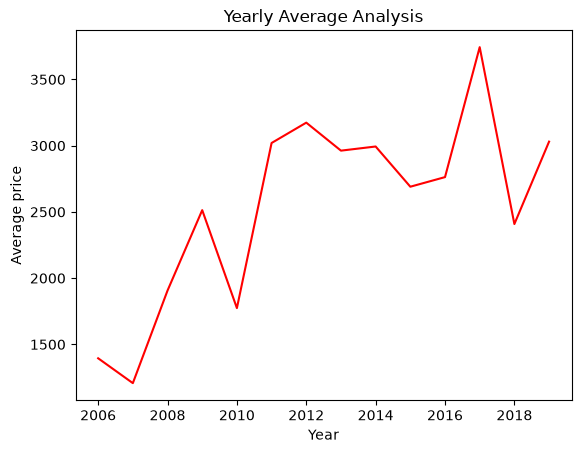

In [131]:
plt.plot(yearly_avg["year"], yearly_avg["avg_price_kes"], color = "red")
plt.xlabel("Year")
plt.ylabel("Average price")
plt.title("Yearly Average Analysis")
plt.show()

In [132]:
# Sell at harvest or hold?
# Average wholesale maize prices by month to find the seasonal pattern. Then compare each market's January and June price, year by year, to see how often storing maize for five months paid off.

# →
# In which month is wholesale maize cheapest on average, and in which is it dearest?
# →
# In what share of market-years was the June price higher than the January price, and what was the median gain?
# →
# What costs and risks of storing maize does this calculation leave out?

In [133]:
# In which month is wholesale maize cheapest on average, and in which is it dearest?
#filtering
maize_wholesale = df[(df['commodity'] == 'Maize') & (df['price_type'] == 'Wholesale')].copy()

#group by month and get the average price per kg
monthly_avg = maize_wholesale.groupby('month')['price_per_kg'].mean().reset_index()

# Sort to see cheapest and dearest
monthly_avg_sorted = monthly_avg.sort_values('price_per_kg')

# cheapest and dearest
cheapest = monthly_avg.loc[monthly_avg['price_per_kg'].idxmin()]
dearest = monthly_avg.loc[monthly_avg['price_per_kg'].idxmax()]
cheapest, dearest


(month            1.0000
 price_per_kg    25.8835
 Name: 0, dtype: float64,
 month            6.000000
 price_per_kg    31.549648
 Name: 5, dtype: float64)

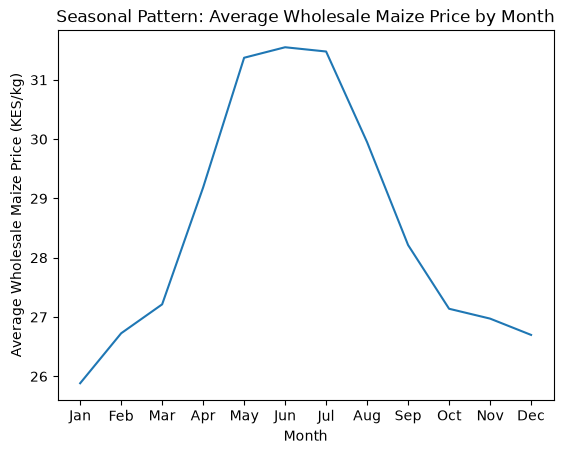

In [134]:
plt.plot(monthly_avg['month'], monthly_avg['price_per_kg'])
plt.xticks(range(1, 13), ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
plt.xlabel('Month')
plt.ylabel('Average Wholesale Maize Price (KES/kg)')
plt.title('Seasonal Pattern: Average Wholesale Maize Price by Month')
plt.show()

In [135]:
# PART 2: Jan vs June, year by year, market by market

# Compare January and June prices for each market-year
market_year_prices = (maize_wholesale[maize_wholesale["month"].isin([1, 6])]
    .groupby(["market", "year", "month"])["price_kes"]
    .mean()
    .unstack("month")
    .rename(columns={1: "January", 6: "June"})
    .dropna(subset=["January", "June"])
)

market_year_prices["gain"] = (market_year_prices["June"] - market_year_prices["January"])
market_year_prices

month         January     June     gain
market  year                           
Eldoret 2006  1192.00  1549.00   357.00
        2007   947.50  1204.71   257.21
        2008  1200.00  1776.00   576.00
        2009  1743.00  2776.00  1033.00
        2010  2142.00  1556.00  -586.00
        2011  1390.00  3800.00  2410.00
        2012  2800.00  2960.00   160.00
        2013  2642.00  2710.00    68.00
        2014  2794.00  3100.00   306.00
        2015  2000.00  2550.00   550.00
        2016  2210.00  2600.00   390.00
        2017  2780.00  4320.00  1540.00
        2018  2485.00  2030.00  -455.00
        2019  1684.00  3200.00  1516.00
Kisumu  2006  1320.00  1714.00   394.00
        2007  1400.00  1272.22  -127.78
        2009  2800.00  2633.00  -167.00
        2010  2395.00  1724.00  -671.00
        2011  2031.00  4620.00  2589.00
        2012  3600.00  4280.00   680.00
        2013  3200.00  3600.00   400.00
        2014  3600.00  3929.00   329.00
        2015  3200.00  3100.00  -100.00
        2016  3200.00  3200.00     0.00
        2017  3600.00  4880.00  1280.00
        2018  3600.00  3200.00  -400.00
        2019  2600.00  4240.00  1640.00
Mombasa 2006  1480.00  1814.75   334.75
        2007  1061.90  1200.00   138.10
        2008  1431.58  1909.29   477.71
        2009  2098.75  2435.00   336.25
        2010  2306.67  1526.00  -780.67
        2011  1710.00  3800.00  2090.00
        2012  3020.00  3375.00   355.00
        2013  1545.00  2835.00  1290.00
        2014  3000.00  3288.00   288.00
        2015  2372.00  3013.00   641.00
        2016  2700.00  2670.00   -30.00
        2017  3135.00  4806.50  1671.50
        2018  2808.00  2690.00  -118.00
        2019  2305.00  3317.50  1012.50
Nairobi 2006  1399.00  1550.91   151.91
        2007  1337.50  1204.44  -133.06
        2008  1347.00  2165.00   818.00
        2009  2221.00  2854.00   633.00
        2010  2525.00  1948.00  -577.00
        2011  2000.00  3800.00  1800.00
        2012  3000.00  3650.00   650.00
        2013  3000.00  3020.00    20.00
        2014  3225.00  3344.00   119.00
        2015  2356.00  2850.00   494.00
        2016  2525.00  2484.00   -41.00
        2017  3042.00  4816.00  1774.00
        2018  3000.00  2662.50  -337.50
        2019  2296.00  3609.75  1313.75
Nakuru  2015  2088.00  2650.00   562.00
        2016  2300.00  2400.00   100.00
        2017  2620.00  4000.00  1380.00
        2018  2460.00  2245.00  -215.00
        2019  1500.00  2700.00  1200.00

In [136]:
maize_wholesale = df[(df["commodity"] == "Maize") & (df["price_type"] == "Wholesale")].copy()


# Calculate the share of market-years where June was higher than January and the median gain
share_higher = (market_year_prices["gain"] > 0).mean() * 100
median_gain = market_year_prices["gain"].median()

print(f"June was higher than January in {share_higher:.1f}% " "of market-years.")
print(f"Median June-minus-January gain: KES {median_gain:.2f}")

June was higher than January in 73.3% of market-years.
Median June-minus-January gain: KES 356.00


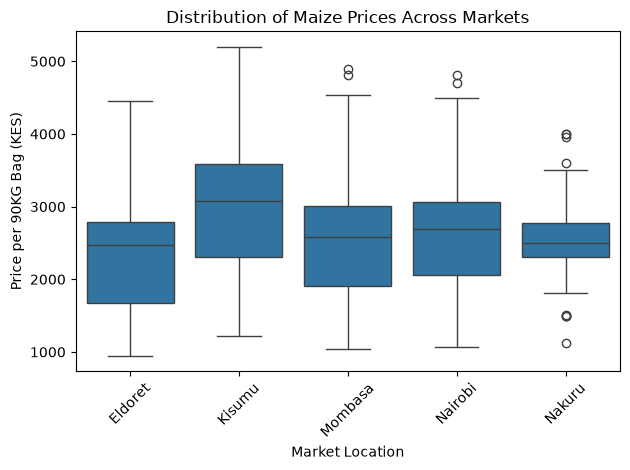

In [137]:

# 2. Draw the boxplot
sns.boxplot(data=df_maize, x="market", y="price_kes")
plt.title("Distribution of Maize Prices Across Markets")
plt.xlabel("Market Location")
plt.ylabel("Price per 90KG Bag (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

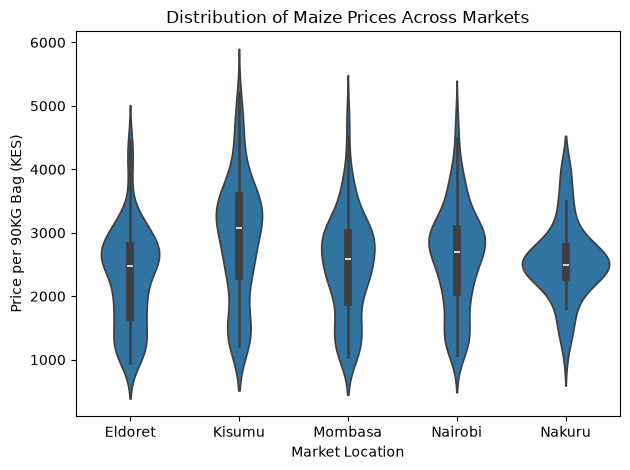

In [145]:
sns.violinplot(data=df_maize, x="market", y="price_kes")
# 2. Add the clean descriptive text layers
plt.title("Distribution of Maize Prices Across Markets")
plt.xlabel("Market Location")
plt.ylabel("Price per 90KG Bag (KES)")

# 3. Clean and display
plt.tight_layout()
plt.show()

In [138]:
## What costs and risks of storing maize does this calculation leave out?
# -Pests - Weevils & Rats
# -Theft & Fire
# -Quality Loss
# -Need for Cash

In [139]:
# 5 Where households pay most, and your advice
# Compare average retail maize prices across the nine county markets for 2015 to 2019, then rank the markets within each year. Write your note for Pamoja with advice backed by your numbers.

# →
# Which retail market was the most expensive on average from 2015 to 2019, and which was the cheapest?
# →
# Which markets ranked in the top three every single year?
# →
# What would you tell a farmer group about when to sell, and which markets should county officers watch?

In [140]:
#filtering 
retail_maize = df[(df["commodity"] == "Maize") & (df["price_type"] == "Retail") &(df['year'].between(2015, 2019))].copy()
print(retail_maize["market"].nunique())
print(retail_maize["year"].unique())

9
[2015 2016 2017 2018 2019]


In [141]:
#Average price for each market in each year


market_avg = retail_maize.groupby("market")["price_per_kg"].mean().sort_values(ascending=False)
print(market_avg)

market
Lodwar      75.847458
Mandera     67.532203
Garissa     59.728814
Kajiado     50.878136
Hola        49.870508
Marsabit    47.503448
Marigat     46.532143
Kilifi      43.842373
Kitui       36.191000
Name: price_per_kg, dtype: float64


In [142]:
market_year = retail_maize.groupby(["market", "year"])["price_per_kg"].mean().reset_index()

market_year["rank"] = market_year.groupby("year")["price_per_kg"].rank(ascending=False)
print(market_year[market_year["year"] == 2019].sort_values("rank"))

      market  year  price_per_kg  rank
34   Mandera  2019     76.725000   1.0
4    Garissa  2019     66.583333   2.0
29    Lodwar  2019     64.825000   3.0
9       Hola  2019     56.025000   4.0
14   Kajiado  2019     50.433333   5.0
39   Marigat  2019     48.644444   6.0
44  Marsabit  2019     46.775000   7.0
19    Kilifi  2019     45.000000   8.0
24     Kitui  2019     38.866667   9.0


In [143]:
top3 = market_year[market_year["rank"] <= 3]
print(top3.groupby("market")["year"].nunique())

market
Garissa    4
Kajiado    1
Lodwar     5
Mandera    5
Name: year, dtype: int64


In [144]:
print(market_year.pivot(index="market", columns="year", values="rank"))

year      2015  2016  2017  2018  2019
market                                
Garissa    3.0   3.0   4.0   3.0   2.0
Hola       7.0   4.0   5.0   4.0   4.0
Kajiado    5.0   5.0   3.0   5.0   5.0
Kilifi     8.0   8.0   7.0   7.0   8.0
Kitui      9.0   9.0   9.0   9.0   9.0
Lodwar     1.0   1.0   1.0   1.0   3.0
Mandera    2.0   2.0   2.0   2.0   1.0
Marigat    6.0   7.0   6.0   8.0   6.0
Marsabit   4.0   6.0   8.0   6.0   7.0
